# 08 - Final results and report figures (Week 9)

Six report figures (150 dpi, colour-blind-safe Okabe-Ito palette, colour never the only cue) saved to `outputs/plots/final/`.
Nothing is recomputed here: the notebook only reads `outputs/results/week8_results.csv` (Week 8), `outputs/results/week9_gradcam.csv` (notebook 07)
and `outputs/audit/leak_summary.csv` (Weeks 3-4). Figure code: `src/report.py`. The summary at the end only describes what the printed numbers say.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image as ShowImage, display
from src import report as rp
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
res = pd.read_csv('outputs/results/week8_results.csv')
gcam = pd.read_csv('outputs/results/week9_gradcam.csv')
leak = pd.read_csv('outputs/audit/leak_summary.csv', index_col=0)
print(len(res), 'runs |', len(gcam), 'Grad-CAM images |', 'leak table:', list(leak.index))

12 runs | 11600 Grad-CAM images | leak table: ['v1', 'v2']


D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Figure 1 - original vs clean split (MAIN RESULT)
Each pair of dots = one model on one dataset version: hollow = original split, filled = clean split. A star marks a run that stopped early, so the two runs of a pair did **not** get the same training budget.

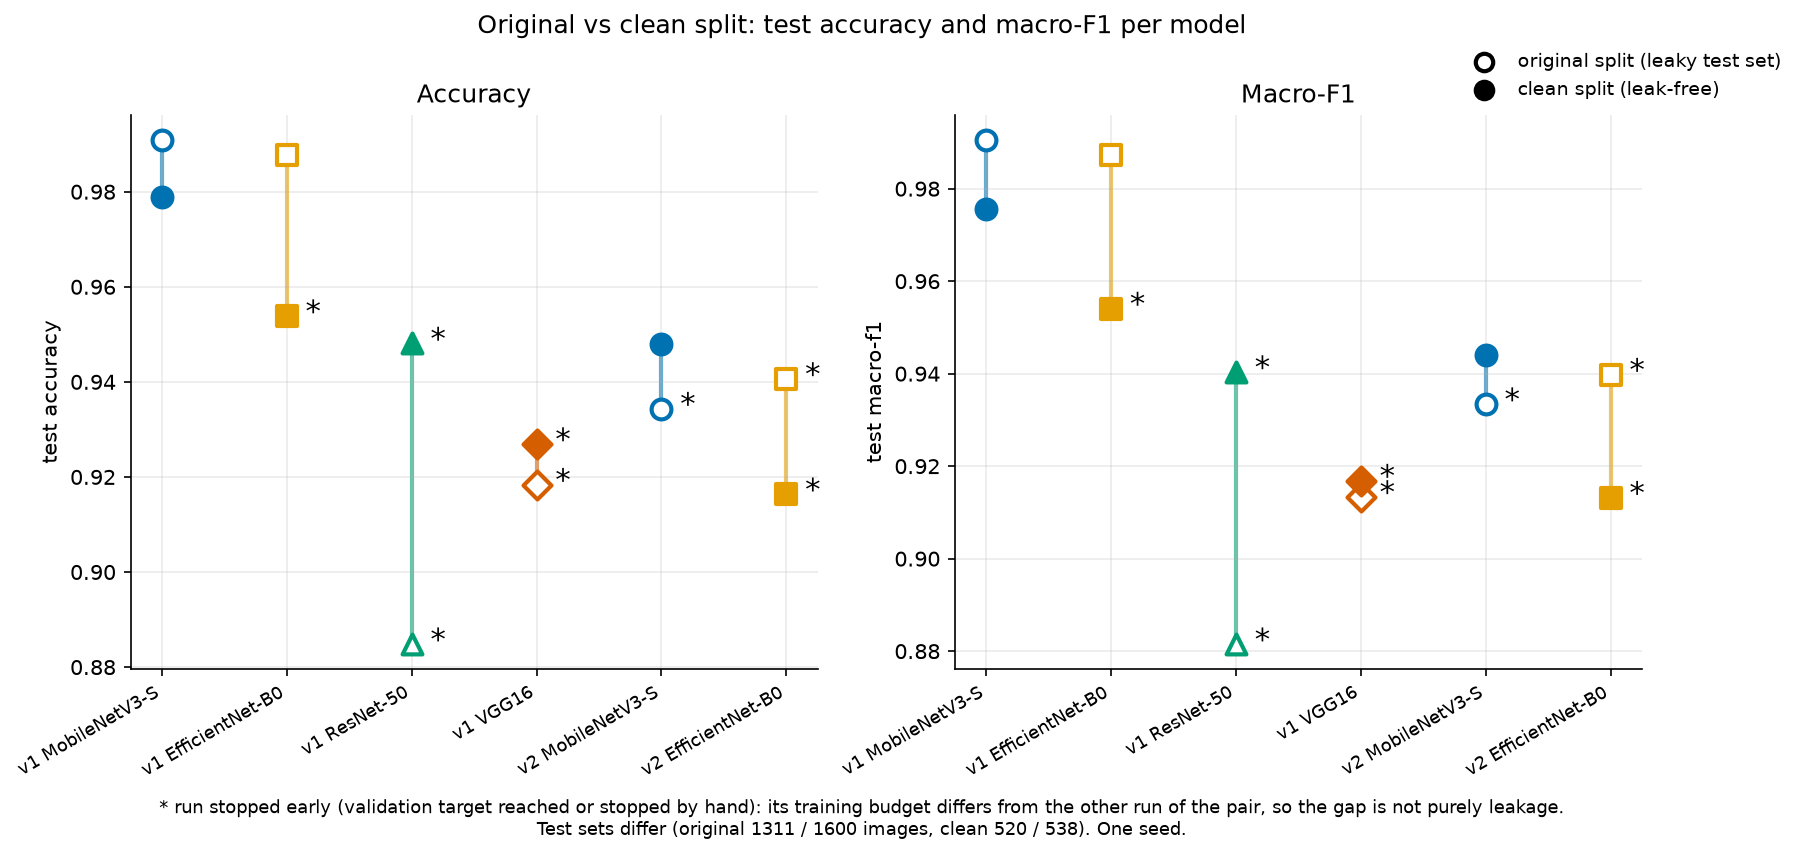

accuracy          macro_f1                  accuracy         macro_f1 early-stopped runs
split                            clean original    clean original original - clean original - clean                   
version model                                                                                                         
v1      efficientnet_b0         0.9538   0.9878   0.9541   0.9872           0.0339           0.0331              clean
        mobilenetv3_small_100   0.9788   0.9908   0.9756   0.9905           0.0120           0.0149               none
        resnet50                0.9481   0.8848   0.9404   0.8815          -0.0633          -0.0589    original, clean
        vgg16                   0.9269   0.9184   0.9169   0.9134          -0.0085          -0.0035    original, clean
v2      efficientnet_b0         0.9164   0.9406   0.9132   0.9398           0.0243           0.0266    original, clean
        mobilenetv3_small_100   0.9480   0.9344   0.9440   0.9334          -0.0136          -0.0105           original

In [2]:
display(ShowImage(str(rp.fig1_original_vs_clean(res))))
t = res.pivot_table(index=['version', 'model'], columns='split', values=['accuracy', 'macro_f1'])
t[('accuracy', 'original - clean')] = t[('accuracy', 'original')] - t[('accuracy', 'clean')]
t[('macro_f1', 'original - clean')] = t[('macro_f1', 'original')] - t[('macro_f1', 'clean')]
early = res.assign(run=res['version'] + '_' + res['split'] + '_' + res['model']).set_index('run')['stopped_by']
t['early-stopped runs'] = [', '.join(s for s in ('original', 'clean') if early[f'{v}_{s}_{m}'] in ('target_acc', 'user_stop')) or 'none' for v, m in t.index]
t.round(4)

## Figure 2 - model size vs macro-F1 (log x-axis)

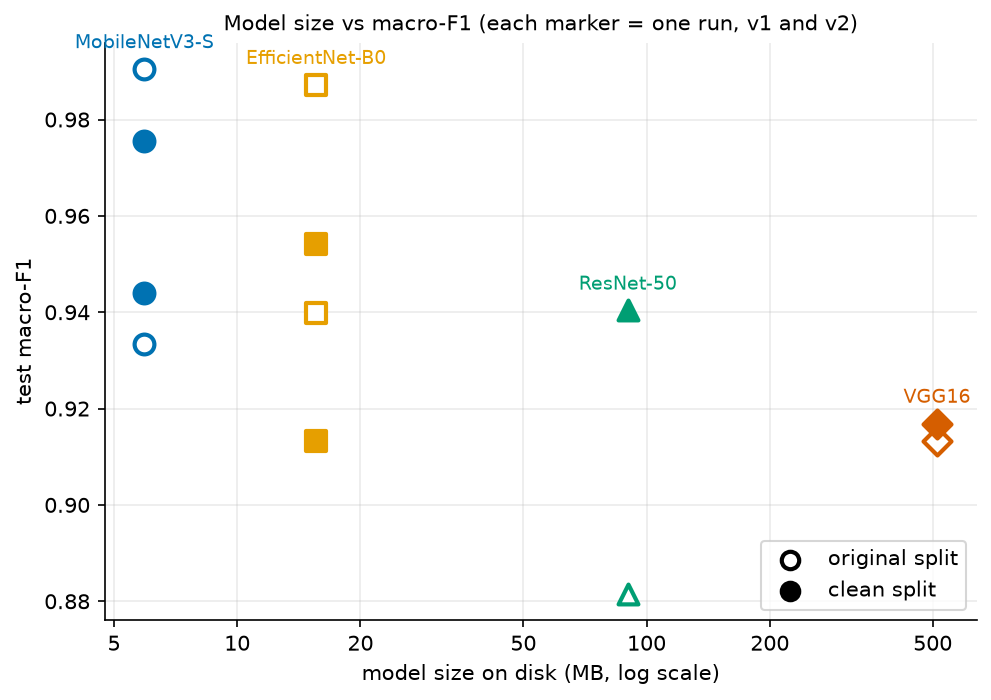

,version,model,params_M,size_mb,cpu_ms,macro_f1
0,v1,efficientnet_b0,4.013,15.588,24.230,0.954
1,v1,mobilenetv3_small_100,1.522,5.932,8.144,0.976
2,v1,resnet50,23.516,90.013,58.785,0.940
3,v1,vgg16,134.277,512.237,282.997,0.917
8,v2,efficientnet_b0,4.013,15.588,22.969,0.913
9,v2,mobilenetv3_small_100,1.522,5.932,8.914,0.944


In [3]:
display(ShowImage(str(rp.fig2_size_vs_f1(res))))
res[res['split'] == 'clean'][['version', 'model', 'params_M', 'size_mb', 'cpu_ms', 'macro_f1']].round(3)

## Figure 3 - per-class sensitivity (v1: all four models; the v2 numbers are in the table below)

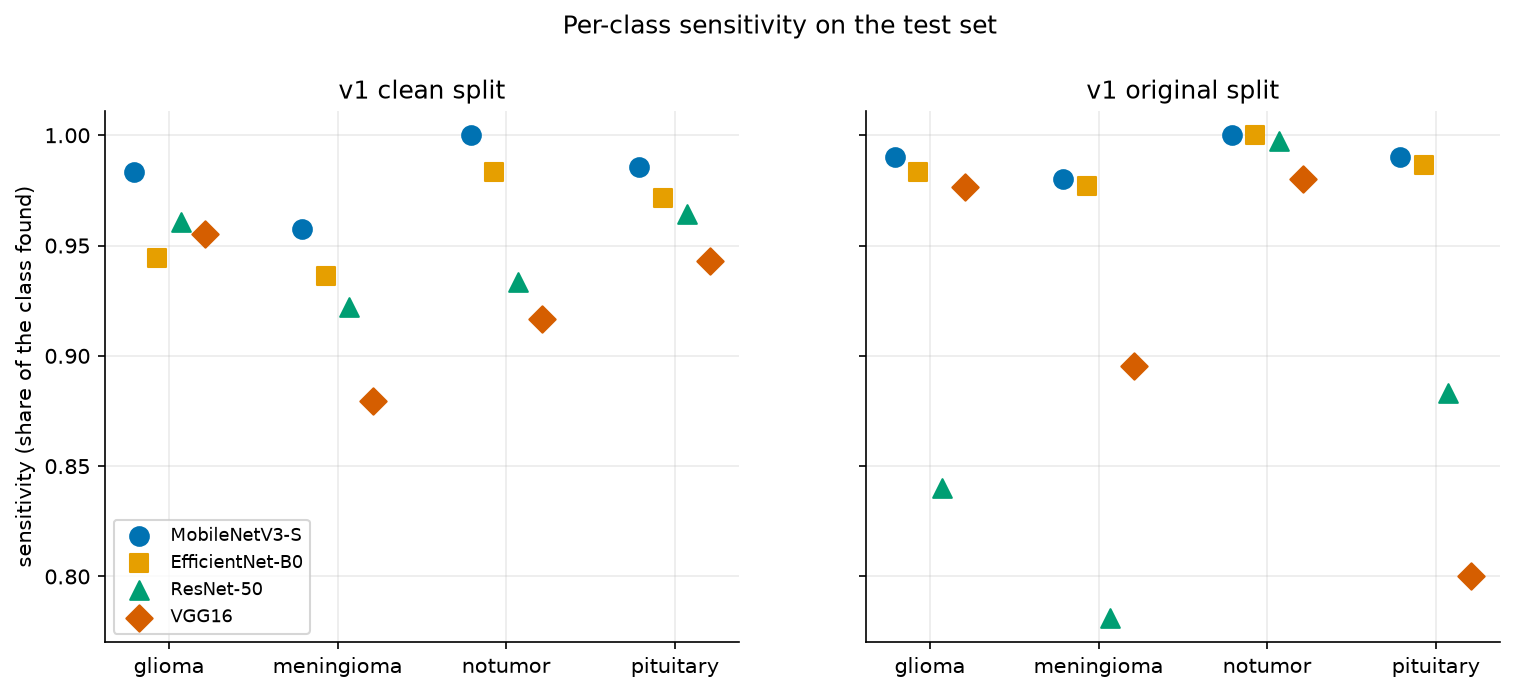

,split,model,sens_glioma,sens_meningioma,sens_notumor,sens_pituitary
8,clean,efficientnet_b0,0.888,0.893,0.966,0.958
9,clean,mobilenetv3_small_100,0.963,0.893,0.983,0.972
10,original,efficientnet_b0,0.818,0.965,0.998,0.982
11,original,mobilenetv3_small_100,0.838,0.908,1.000,0.992


In [4]:
display(ShowImage(str(rp.fig3_sensitivity(res))))
res[res['version'] == 'v2'][['split', 'model'] + [f'sens_{c}' for c in rp.CLASSES]].round(3)

## Figure 4 - ECE before / after temperature scaling

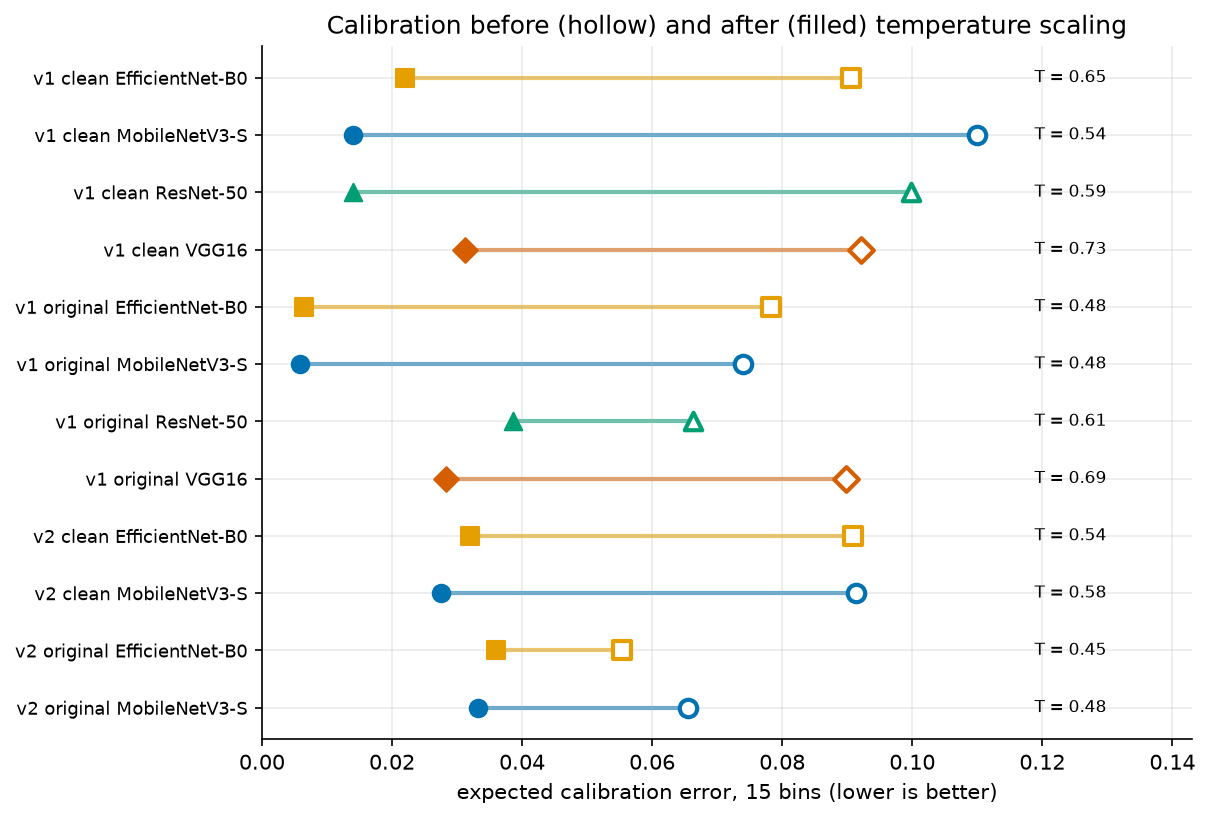

,version,split,model,temperature,ece_before,ece_after
0,v1,clean,efficientnet_b0,0.6501,0.0906,0.0220
1,v1,clean,mobilenetv3_small_100,0.5371,0.1100,0.0140
2,v1,clean,resnet50,0.5920,0.0998,0.0141
3,v1,clean,vgg16,0.7332,0.0921,0.0312
4,v1,original,efficientnet_b0,0.4775,0.0782,0.0065
5,v1,original,mobilenetv3_small_100,0.4772,0.0740,0.0059
6,v1,original,resnet50,0.6086,0.0663,0.0385
7,v1,original,vgg16,0.6866,0.0898,0.0282
8,v2,clean,efficientnet_b0,0.5353,0.0909,0.0320
9,v2,clean,mobilenetv3_small_100,0.5790,0.0914,0.0276


In [5]:
display(ShowImage(str(rp.fig4_ece(res))))
res[['version', 'split', 'model', 'temperature', 'ece_before', 'ece_after']].round(4)

## Figure 5 - Grad-CAM inside-brain ratio per model
Boxes pool all runs of a model (v1 and v2). The dashed line is the average share of the picture covered by the brain: a uniform heat map would score that.

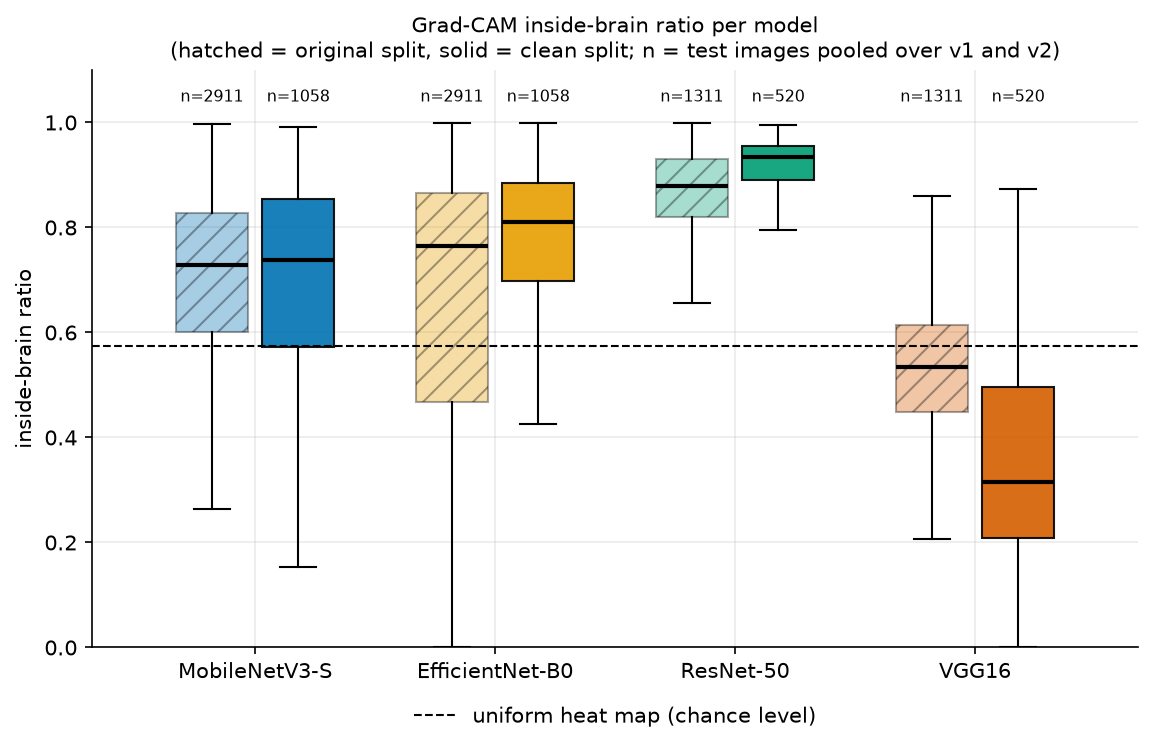

n  ratio_mean  ratio_median  chance  over_chance_median
model                 split                                                               
efficientnet_b0       clean     1058       0.772         0.810   0.578               1.348
                      original  2911       0.674         0.765   0.574               1.275
mobilenetv3_small_100 clean     1058       0.694         0.737   0.578               1.238
                      original  2911       0.699         0.729   0.574               1.237
resnet50              clean      520       0.899         0.934   0.579               1.543
                      original  1311       0.849         0.880   0.572               1.486
vgg16                 clean      520       0.353         0.315   0.579               0.523
                      original  1311       0.531         0.534   0.572               0.906

In [6]:
display(ShowImage(str(rp.fig5_inside_ratio(gcam))))
g = gcam.assign(split=gcam['run'].str.split('_').str[1])
g.groupby(['model', 'split']).agg(n=('row', 'size'), ratio_mean=('inside_ratio', 'mean'), ratio_median=('inside_ratio', 'median'),
                                  chance=('mask_frac', 'mean'), over_chance_median=('ratio_over_chance', 'median')).round(3)

## Figure 6 - leakage per dataset version

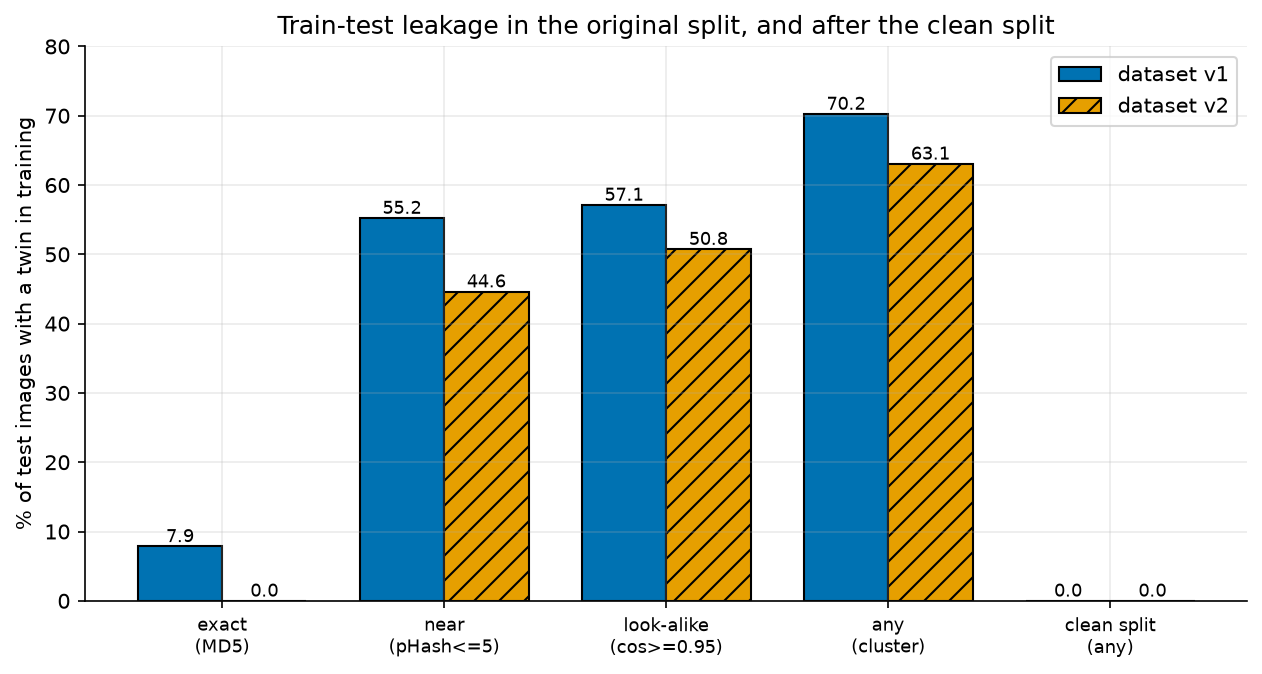

,exact (MD5),near (pHash<=5),look-alike (cos>=0.95),any (cluster),clean split (any)
v1,7.86,55.23,57.13,70.25,0.0
v2,0.00,44.62,50.75,63.06,0.0


In [7]:
display(ShowImage(str(rp.fig6_leakage(leak))))
leak

## What the results show (plain English)

Everything below is read from the tables and figures above. One seed per model, small test sets (clean split: 520 and 538 images, so one image is about 0.19 points), so differences of about one point should not be over-read.

**1. Leakage in the original split is large (figure 6).** In the original Testing folder, 7.9% of the v1 test images (0% for v2) are exact copies of a training image, 55.2% (v1) and 44.6% (v2) have a near-duplicate in training, and 70.2% (v1) and 63.1% (v2) belong to a cluster that also appears in training. After our clean split this is 0% by construction.

**2. Our main hypothesis, "the clean split gives lower scores", is not confirmed by these runs (figure 1).** The original-split score is higher than the clean one in 3 of the 6 model-version pairs and lower in the other 3. The pairs are not comparable because training stopped early in most of them: for example ResNet-50 (3 epochs) and VGG16 (5 epochs, stopped by hand) on the original split scored *below* their clean runs (accuracy 0.885 vs 0.948 and 0.918 vs 0.927), which reflects under-training, not leakage. The only pair where both runs trained to patience or the epoch limit is v1 MobileNetV3-S: accuracy 0.9908 (original) vs 0.9788 (clean), macro-F1 0.9905 vs 0.9756, a drop of about 1.2 and 1.5 points. That is consistent with some inflation, but it is a single pair. A fair test needs equal training budgets, which we did not run.

**3. Light models are not worse than the heavy baselines in our runs (figure 2).** On the v1 clean split the test macro-F1 is 0.9756 (MobileNetV3-S, 5.9 MB), 0.9541 (EfficientNet-B0, 15.6 MB), 0.9404 (ResNet-50, 90 MB) and 0.9169 (VGG16, 512 MB). The heavy runs also stopped early, so we cannot say they would not catch up with more training. What the numbers do show is the cost: VGG16 needed about 283 ms per image on this CPU against about 8 ms for MobileNetV3-S.

**4. Weak spot by class (figure 3).** On the v1 clean split meningioma has the lowest sensitivity for all four models (0.957 MobileNetV3-S, 0.936 EfficientNet-B0, 0.922 ResNet-50, 0.879 VGG16). Notumor sensitivity is at least 0.917 for every model on that split, but note that it has only 60 test images.

**5. Calibration (figure 4).** All 12 runs were under-confident (T between 0.45 and 0.73, likely a side effect of label smoothing). Temperature scaling lowered the ECE in every run, from 0.055-0.110 to 0.006-0.039. Referring scans below 0.70 confidence sent 0.3-12% of scans to a radiologist, and accuracy on the scans not referred was higher than overall accuracy in all 12 runs.

**6. Grad-CAM (figure 5).** The inside-brain ratio is highest for ResNet-50 (mean 0.899 on v1 clean), then EfficientNet-B0, then MobileNetV3-S, and lowest for VGG16 (0.353 on v1 clean, below the 0.58 a uniform heat map would give; its heat sits on the skull rim and picture borders). This ordering does not follow model size or accuracy, so the idea that lightweight models look at the brain more than heavy ones is not supported. The ratio did not separate correct from wrong predictions (wrong was lower in 7 of 12 runs and higher in 5, with only 11-151 wrong images per run). The "brain mask" is really a head-tissue mask (it includes skull and scalp and fails on very bright tumours), so a high ratio does not prove the model looks at the tumour.

**What we can and cannot claim.** We can claim: the original split leaks heavily; temperature scaling fixes under-confidence in every run; the lightweight models match the heavy ones at a small fraction of the size and CPU time; and VGG16's Grad-CAM heat lies more on the picture edge than on the brain (a warning sign; we did not test causally whether it relies on the background). We cannot claim: that leakage inflates accuracy by a specific amount (only one fair pair), that heavy models are worse in general (they stopped early), or that Grad-CAM proves what any network uses.

In [8]:
Path('outputs/results').mkdir(parents=True, exist_ok=True)
Path('outputs/results/week9_summary.md').write_text('Everything below is read from the tables and figures above. One seed per model, small test sets (clean split: 520 and 538 images, so one image is about 0.19 points), so differences of about one point should not be over-read.\n\n**1. Leakage in the original split is large (figure 6).** In the original Testing folder, 7.9% of the v1 test images (0% for v2) are exact copies of a training image, 55.2% (v1) and 44.6% (v2) have a near-duplicate in training, and 70.2% (v1) and 63.1% (v2) belong to a cluster that also appears in training. After our clean split this is 0% by construction.\n\n**2. Our main hypothesis, "the clean split gives lower scores", is not confirmed by these runs (figure 1).** The original-split score is higher than the clean one in 3 of the 6 model-version pairs and lower in the other 3. The pairs are not comparable because training stopped early in most of them: for example ResNet-50 (3 epochs) and VGG16 (5 epochs, stopped by hand) on the original split scored *below* their clean runs (accuracy 0.885 vs 0.948 and 0.918 vs 0.927), which reflects under-training, not leakage. The only pair where both runs trained to patience or the epoch limit is v1 MobileNetV3-S: accuracy 0.9908 (original) vs 0.9788 (clean), macro-F1 0.9905 vs 0.9756, a drop of about 1.2 and 1.5 points. That is consistent with some inflation, but it is a single pair. A fair test needs equal training budgets, which we did not run.\n\n**3. Light models are not worse than the heavy baselines in our runs (figure 2).** On the v1 clean split the test macro-F1 is 0.9756 (MobileNetV3-S, 5.9 MB), 0.9541 (EfficientNet-B0, 15.6 MB), 0.9404 (ResNet-50, 90 MB) and 0.9169 (VGG16, 512 MB). The heavy runs also stopped early, so we cannot say they would not catch up with more training. What the numbers do show is the cost: VGG16 needed about 283 ms per image on this CPU against about 8 ms for MobileNetV3-S.\n\n**4. Weak spot by class (figure 3).** On the v1 clean split meningioma has the lowest sensitivity for all four models (0.957 MobileNetV3-S, 0.936 EfficientNet-B0, 0.922 ResNet-50, 0.879 VGG16). Notumor sensitivity is at least 0.917 for every model on that split, but note that it has only 60 test images.\n\n**5. Calibration (figure 4).** All 12 runs were under-confident (T between 0.45 and 0.73, likely a side effect of label smoothing). Temperature scaling lowered the ECE in every run, from 0.055-0.110 to 0.006-0.039. Referring scans below 0.70 confidence sent 0.3-12% of scans to a radiologist, and accuracy on the scans not referred was higher than overall accuracy in all 12 runs.\n\n**6. Grad-CAM (figure 5).** The inside-brain ratio is highest for ResNet-50 (mean 0.899 on v1 clean), then EfficientNet-B0, then MobileNetV3-S, and lowest for VGG16 (0.353 on v1 clean, below the 0.58 a uniform heat map would give; its heat sits on the skull rim and picture borders). This ordering does not follow model size or accuracy, so the idea that lightweight models look at the brain more than heavy ones is not supported. The ratio did not separate correct from wrong predictions (wrong was lower in 7 of 12 runs and higher in 5, with only 11-151 wrong images per run). The "brain mask" is really a head-tissue mask (it includes skull and scalp and fails on very bright tumours), so a high ratio does not prove the model looks at the tumour.\n\n**What we can and cannot claim.** We can claim: the original split leaks heavily; temperature scaling fixes under-confidence in every run; the lightweight models match the heavy ones at a small fraction of the size and CPU time; and VGG16\'s Grad-CAM heat lies more on the picture edge than on the brain (a warning sign; we did not test causally whether it relies on the background). We cannot claim: that leakage inflates accuracy by a specific amount (only one fair pair), that heavy models are worse in general (they stopped early), or that Grad-CAM proves what any network uses.\n', encoding='utf-8')
print('summary saved to outputs/results/week9_summary.md;', len(list(Path('outputs/plots/final').glob('*.png'))), 'figures in outputs/plots/final')

summary saved to outputs/results/week9_summary.md; 6 figures in outputs/plots/final
